# Quantum Computing Basics: From Bits to Qubits (with a Simulator You Build Yourself)

> **Who is this for:** AI and software engineers who have never studied quantum physics. You only need school algebra, a little Python and numpy.
>
> **What you will learn:**
> - the difference between a **bit** and a **qubit**, and what **superposition** really means
> - **amplitudes** and **probabilities** (the Born rule), and what **measurement** does
> - the **Bloch sphere** picture of one qubit
> - the common **gates**: X, Z, H, S, T, RX, RY, RZ and CNOT, and why they are matrices
> - **multi-qubit states**, the **tensor product**, and why classical computers struggle to simulate many qubits
> - **entanglement** (the Bell state), **interference** and the **no-cloning** theorem
> - how to **build a small statevector simulator in numpy** (apply gates, measure with shots, draw a histogram). Notebooks 02-04 reuse it.
>
> **Prerequisites:** [Linear algebra](../14_Mathematics/01_linear_algebra.ipynb) (vectors, matrices, matrix-vector product) and [Probability](../14_Mathematics/03_probability.ipynb) (probabilities add up to 1, sampling). Complex numbers are explained here when we need them.
>
> **Time needed:** about 2-3 hours to read and play. The notebook itself runs in a few seconds.
>
> **Runs on:** CPU, no API key, no internet. Only numpy and matplotlib. No quantum library is needed.

## 0. Setup

We only need numpy (arrays and matrices) and matplotlib (plots). We fix the random seed so that the "random" measurement results are the same every time you run the notebook.

In [1]:
import numpy as np                     # vectors and matrices
import matplotlib.pyplot as plt        # plots
from collections import Counter        # counting measurement results

SEED = 42
rng = np.random.default_rng(SEED)      # one random generator for the whole notebook
np.set_printoptions(precision=3, suppress=True)
print("numpy", np.__version__)

numpy 2.5.4


## 1. Why quantum computing? Bits vs qubits

**What it is.** A **bit** is the smallest unit of classical information. It is always either 0 or 1. A **qubit** (quantum bit) is the smallest unit of quantum information. Before you look at it, a qubit can be in a **superposition**: a mix of 0 and 1 described by two numbers called **amplitudes**. When you look at it (**measure** it), you always get a plain 0 or 1.

**Simple analogy.** A bit is a coin lying on the table: heads or tails. A qubit is more like a spinning coin. While it spins it is not "secretly heads" or "secretly tails"; it has a *direction of spin* that decides the odds. When you slap it down (measure), you get heads or tails, and the spin is gone.

The analogy has a limit. Real amplitudes can be **negative or complex**, so they can *cancel* each other out (**interference**). Coins cannot do that, and interference is where the useful quantum effects come from.

**How it works (big picture).**

```mermaid
flowchart LR
    A[Prepare qubits in 0] --> B[Apply gates<br/>rotate amplitudes]
    B --> C[Interference makes<br/>good answers likely]
    C --> D[Measure<br/>get classical bits]
    D --> E[Repeat many shots<br/>and count results]
```

| | Classical bit | Qubit |
|---|---|---|
| Possible values while computing | 0 or 1 | a superposition $\alpha\lvert0\rangle + \beta\lvert1\rangle$ |
| What you read out | 0 or 1 | 0 or 1 (randomly, with probabilities $\lvert\alpha\rvert^2$, $\lvert\beta\rvert^2$) |
| Can you copy it? | yes | no (no-cloning theorem, section 10) |
| n of them describe | one of $2^n$ values | $2^n$ amplitudes at once |
| Operations | logic gates (AND, OR, NOT) | reversible **unitary** gates (rotations) |

**When it helps and when not.** Quantum computers are *not* faster at everything. They help only for problems with a special structure that interference can exploit (factoring, simulating molecules, some search problems). For everyday tasks (web servers, spreadsheets, training most neural networks) classical computers are better and will stay better. Notebook 02 has a table of which problems have known speedups.

A common myth: "a qubit stores 0 and 1 at the same time, so n qubits try all $2^n$ answers in parallel". This is misleading. You cannot read out all $2^n$ amplitudes; one measurement gives you only n bits. The trick of every quantum algorithm is to arrange interference so that the **right** answer becomes likely before you measure.

## 2. A qubit is a vector of two amplitudes

**What it is.** We write the two basic states with "ket" notation (**Dirac notation**): $\lvert 0\rangle$ and $\lvert 1\rangle$. A ket is just a column vector:

$$\lvert 0\rangle = \begin{pmatrix}1\\0\end{pmatrix}, \quad \lvert 1\rangle = \begin{pmatrix}0\\1\end{pmatrix}, \quad \lvert\psi\rangle = \alpha\lvert0\rangle + \beta\lvert1\rangle = \begin{pmatrix}\alpha\\ \beta\end{pmatrix}$$

The numbers $\alpha$ and $\beta$ are the **amplitudes**. They can be **complex numbers** (numbers of the form $a + bi$ with $i^2=-1$). In Python, `1j` is $i$.

**The Born rule.** When you measure, you get 0 with probability $\lvert\alpha\rvert^2$ and 1 with probability $\lvert\beta\rvert^2$. ($\lvert z\rvert^2$ is "the size of $z$, squared"; for $z=a+bi$ it is $a^2+b^2$.) Because probabilities must add up to 1, every valid state is **normalised**: $\lvert\alpha\rvert^2 + \lvert\beta\rvert^2 = 1$.

**Simple analogy.** Think of an arrow of length 1. Its "shadow" on the 0-axis and on the 1-axis are the amplitudes. The squared shadows are the probabilities, and by Pythagoras they add up to 1.

In [2]:
ket0 = np.array([1, 0], dtype=complex)        # |0>
ket1 = np.array([0, 1], dtype=complex)        # |1>

plus  = (ket0 + ket1) / np.sqrt(2)            # |+> : equal superposition
minus = (ket0 - ket1) / np.sqrt(2)            # |-> : equal superposition with a minus sign
odd   = np.sqrt(0.8) * ket0 + 1j * np.sqrt(0.2) * ket1   # 80/20 mix with a complex amplitude

for name, psi in [("|0>", ket0), ("|+>", plus), ("|->", minus), ("odd", odd)]:
    probs = np.abs(psi) ** 2                  # Born rule: probability = |amplitude|^2
    print(f"{name:4}  amplitudes {psi}   P(0)={probs[0]:.2f}  P(1)={probs[1]:.2f}   total={probs.sum():.2f}")

|0>   amplitudes [1.+0.j 0.+0.j]   P(0)=1.00  P(1)=0.00   total=1.00
|+>   amplitudes [0.707+0.j 0.707+0.j]   P(0)=0.50  P(1)=0.50   total=1.00
|->   amplitudes [ 0.707+0.j -0.707+0.j]   P(0)=0.50  P(1)=0.50   total=1.00
odd   amplitudes [0.894+0.j    0.   +0.447j]   P(0)=0.80  P(1)=0.20   total=1.00


**What just happened?** $\lvert+\rangle$ and $\lvert-\rangle$ give exactly the same probabilities (50/50), but they are **different states**: the sign of the second amplitude differs. That sign is called a **relative phase**. You cannot see it with one measurement, but gates can turn it into a visible difference (section 9, interference). This is the first big difference from a coin.

## 3. Measurement and shots

**What it is.** **Measurement** reads a qubit and gives a classical bit. It is random, with the Born-rule probabilities, and it **destroys** the superposition: after measuring 1, the qubit *is* $\lvert1\rangle$ (this is called **collapse**).

**Simple analogy.** A weather forecast says "70% rain". One day tells you almost nothing about the 70%. Only by watching many days do you see the number. Quantum programs are the same: you run the same circuit many times. Each run is a **shot**, and you count the results.

**How it works.** To simulate a measurement we draw random outcomes with the probabilities $\lvert\alpha\rvert^2$ and $\lvert\beta\rvert^2$.

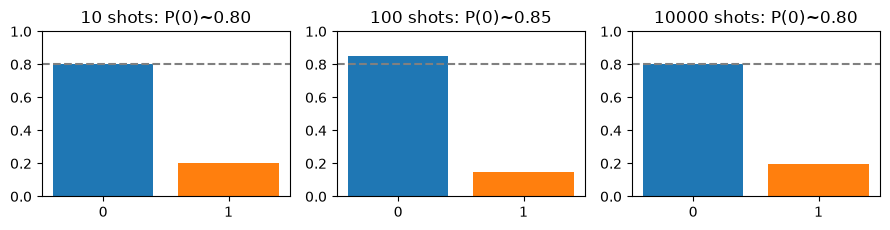

In [3]:
def measure_qubit(psi, shots, rng):
    """Simulate measuring a 1-qubit state `shots` times. Returns counts of '0' and '1'."""
    p = np.abs(psi) ** 2
    outcomes = rng.choice(["0", "1"], size=shots, p=p)
    return Counter(outcomes)

fig, axes = plt.subplots(1, 3, figsize=(9, 2.4))
for ax, shots in zip(axes, [10, 100, 10_000]):
    counts = measure_qubit(odd, shots, rng)            # the 80/20 state from above
    freq = [counts["0"] / shots, counts["1"] / shots]
    ax.bar(["0", "1"], freq, color=["tab:blue", "tab:orange"])
    ax.axhline(0.8, ls="--", c="gray"); ax.set_ylim(0, 1)
    ax.set_title(f"{shots} shots: P(0)~{freq[0]:.2f}")
plt.tight_layout(); plt.show()

**What just happened?** With 10 shots the estimate is rough; with 10,000 shots it is close to the true 0.80 (dashed line). The error of a shot-based estimate shrinks like $1/\sqrt{\text{shots}}$. This matters a lot in practice: **every number you read from a real quantum computer is a noisy estimate**, and getting more precision costs more shots (more time and money).

## 4. The Bloch sphere: a picture of one qubit

**What it is.** Any single-qubit state can be written (ignoring a **global phase**, a common factor $e^{i\gamma}$ that changes nothing you can measure) as

$$\lvert\psi\rangle = \cos\tfrac{\theta}{2}\lvert0\rangle + e^{i\varphi}\sin\tfrac{\theta}{2}\lvert1\rangle$$

The two angles $\theta$ (up-down) and $\varphi$ (around) give a point on a ball of radius 1, the **Bloch sphere**. North pole = $\lvert0\rangle$, south pole = $\lvert1\rangle$, the equator = 50/50 states such as $\lvert+\rangle$ and $\lvert-\rangle$.

**Simple analogy.** A globe. Latitude decides the odds of 0 vs 1. Longitude is the phase: invisible to a measurement, but it changes how the qubit reacts to later gates.

**When to use it.** The Bloch sphere is great for one qubit: every single-qubit gate is just a **rotation of the sphere**. It does *not* work for several entangled qubits, so do not stretch the picture too far.

|0>   -> Bloch (x, y, z) = [0. 0. 1.]
|1>   -> Bloch (x, y, z) = [ 0.  0. -1.]
|+>   -> Bloch (x, y, z) = [1. 0. 0.]
|->   -> Bloch (x, y, z) = [-1.  0.  0.]
|+i>  -> Bloch (x, y, z) = [0. 1. 0.]
odd   -> Bloch (x, y, z) = [0.  0.8 0.6]


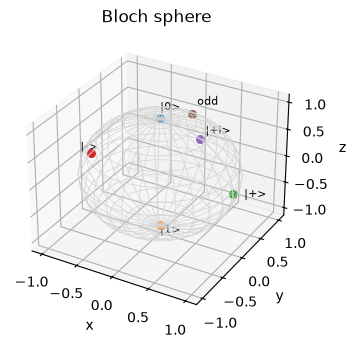

In [4]:
def bloch_xyz(psi):
    """Bloch-sphere coordinates (x, y, z) of a 1-qubit state."""
    a, b = psi
    x = 2 * np.real(np.conj(a) * b)
    y = 2 * np.imag(np.conj(a) * b)
    z = abs(a) ** 2 - abs(b) ** 2
    return np.array([x, y, z])

states = {"|0>": ket0, "|1>": ket1, "|+>": plus, "|->": minus,
          "|+i>": (ket0 + 1j * ket1) / np.sqrt(2), "odd": odd}
for name, psi in states.items():
    print(f"{name:5} -> Bloch (x, y, z) = {bloch_xyz(psi)}")

# small 3-D picture
fig = plt.figure(figsize=(3.6, 3.6)); ax = fig.add_subplot(projection="3d")
u, v = np.mgrid[0:2*np.pi:30j, 0:np.pi:15j]
ax.plot_wireframe(np.cos(u)*np.sin(v), np.sin(u)*np.sin(v), np.cos(v), color="lightgray", lw=0.5)
for name, psi in states.items():
    x, y, z = bloch_xyz(psi); ax.scatter(x, y, z, s=30); ax.text(x*1.15, y*1.15, z*1.15, name, fontsize=8)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z"); ax.set_title("Bloch sphere")
plt.tight_layout(); plt.show()

## 5. Quantum gates are matrices

**What it is.** A **gate** changes the state of one or more qubits. Mathematically it is a **unitary matrix** $U$: a matrix whose inverse is its conjugate transpose ($U^\dagger U = I$). Unitary means "keeps the total probability at 1" and "can always be undone". New state = $U \times$ old state.

**Simple analogy.** Gates are rotations of the Bloch-sphere globe. Rotating never makes the globe bigger or smaller, and you can always rotate back.

| Gate | Matrix | What it does (on the Bloch sphere) | Classical cousin |
|---|---|---|---|
| X | $\begin{pmatrix}0&1\\1&0\end{pmatrix}$ | flips $\lvert0\rangle\leftrightarrow\lvert1\rangle$ (180° about x) | NOT |
| Z | $\begin{pmatrix}1&0\\0&-1\end{pmatrix}$ | flips the sign of $\lvert1\rangle$ (180° about z) | none |
| H (Hadamard) | $\tfrac{1}{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}$ | $\lvert0\rangle\to\lvert+\rangle$, $\lvert1\rangle\to\lvert-\rangle$: makes and un-makes superpositions | none |
| S | $\begin{pmatrix}1&0\\0&i\end{pmatrix}$ | quarter turn about z (phase $i$) | none |
| T | $\begin{pmatrix}1&0\\0&e^{i\pi/4}\end{pmatrix}$ | eighth turn about z | none |
| RX($\theta$), RY($\theta$), RZ($\theta$) | $e^{-i\theta P/2}$ for $P = X, Y, Z$ | rotate by any angle $\theta$ about x, y or z | none |
| CNOT | 4x4, see section 8 | flips the target qubit if the control qubit is 1 | XOR |

The rotation gates have a **parameter** $\theta$ that we can choose freely. Notebooks 02 and 03 tune these angles with a classical optimiser, exactly like weights in a neural network.

Below are the gate matrices. This cell is the first piece of our simulator.

In [5]:
# Single-qubit gates (2x2 matrices)
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
S = np.array([[1, 0], [0, 1j]], dtype=complex)
T = np.array([[1, 0], [0, np.exp(1j * np.pi / 4)]], dtype=complex)

def RX(t): return np.array([[np.cos(t/2), -1j*np.sin(t/2)], [-1j*np.sin(t/2), np.cos(t/2)]], dtype=complex)
def RY(t): return np.array([[np.cos(t/2), -np.sin(t/2)], [np.sin(t/2), np.cos(t/2)]], dtype=complex)
def RZ(t): return np.array([[np.exp(-1j*t/2), 0], [0, np.exp(1j*t/2)]], dtype=complex)

# Two-qubit gates (4x4). The first qubit listed is the control.
CNOT = np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]], dtype=complex)
CZ = np.diag([1, 1, 1, -1]).astype(complex)


# Check: every gate is unitary (U^dagger U = I)
for name, U in [("X", X), ("Y", Y), ("Z", Z), ("H", H), ("S", S), ("T", T), ("RY(0.7)", RY(0.7)), ("CNOT", CNOT)]:
    print(f"{name:8} unitary? {np.allclose(U.conj().T @ U, np.eye(len(U)))}")

X        unitary? True
Y        unitary? True
Z        unitary? True
H        unitary? True
S        unitary? True
T        unitary? True
RY(0.7)  unitary? True
CNOT     unitary? True


In [6]:
# Apply a few gates to |0> and |+> and look at the result
for name, U in [("X", X), ("Z", Z), ("H", H), ("S", S)]:
    print(f"{name}|0> = {U @ ket0}     {name}|+> = {U @ plus}")

X|0> = [0.+0.j 1.+0.j]     X|+> = [0.707+0.j 0.707+0.j]
Z|0> = [1.+0.j 0.+0.j]     Z|+> = [ 0.707+0.j -0.707+0.j]
H|0> = [0.707+0.j 0.707+0.j]     H|+> = [1.+0.j 0.+0.j]
S|0> = [1.+0.j 0.+0.j]     S|+> = [0.707+0.j    0.   +0.707j]


**What just happened?** `X|0> = |1>` (a NOT). `Z|0> = |0>` but `Z|+> = |->`: Z only changes the phase, which you cannot see by measuring straight away. `H|0> = |+>` makes a 50/50 superposition, and `H|+> = |0>` undoes it. Now let us see how a rotation angle smoothly controls the odds.

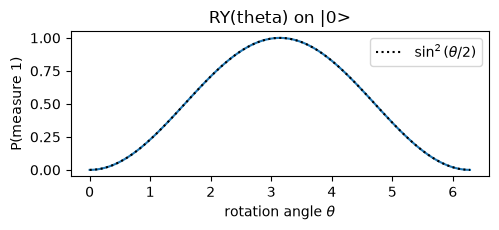

In [7]:
thetas = np.linspace(0, 2 * np.pi, 100)
p1 = [abs((RY(t) @ ket0)[1]) ** 2 for t in thetas]      # P(1) after RY(theta)|0>
plt.figure(figsize=(5, 2.4))
plt.plot(thetas, p1); plt.plot(thetas, np.sin(thetas / 2) ** 2, "k:", label=r"$\sin^2(\theta/2)$")
plt.xlabel(r"rotation angle $\theta$"); plt.ylabel("P(measure 1)"); plt.title("RY(theta) on |0>")
plt.legend(); plt.tight_layout(); plt.show()

## 6. Many qubits: the tensor product

**What it is.** The state of two qubits has $2^2 = 4$ amplitudes, one for each bitstring 00, 01, 10, 11. For n qubits there are $2^n$ amplitudes. If the qubits are independent, the joint state is the **tensor product** (also called the **Kronecker product**, `np.kron`) of the single-qubit states: $\lvert a\rangle\otimes\lvert b\rangle$, written $\lvert ab\rangle$.

**Simple analogy.** One die has 6 outcomes. Two dice have $6\times6=36$ combinations. Each extra qubit doubles the number of combinations, so the list grows very fast.

**Convention used in this track.** In a bitstring like `011`, **qubit 0 is the left-most bit**. (Qiskit uses the opposite order; notebook 04 shows this.)

In [8]:
# |0> on qubit 0 and |+> on qubit 1  ->  |0>(x)|+>
two = np.kron(ket0, plus)
print("|0>(x)|+> =", two, " -> amplitudes for 00, 01, 10, 11")

# Why classical simulation gets hard: memory for 2^n complex numbers (16 bytes each)
def human(nbytes):
    for unit in ["bytes", "KB", "MB", "GB", "TB", "PB"]:
        if nbytes < 1000: return f"{nbytes:,.0f} {unit}"
        nbytes /= 1000
    return f"{nbytes:,.0f} EB"
for n in [10, 20, 30, 40, 50]:
    print(f"{n:2d} qubits: {2**n:>20,d} amplitudes  ~ {human(16 * 2 ** n)}")

|0>(x)|+> = [0.707+0.j 0.707+0.j 0.   +0.j 0.   +0.j]  -> amplitudes for 00, 01, 10, 11
10 qubits:                1,024 amplitudes  ~ 16 KB
20 qubits:            1,048,576 amplitudes  ~ 17 MB
30 qubits:        1,073,741,824 amplitudes  ~ 17 GB
40 qubits:    1,099,511,627,776 amplitudes  ~ 18 TB
50 qubits: 1,125,899,906,842,624 amplitudes  ~ 18 PB


**What just happened?** 30 qubits already need about 17 GB, and 50 qubits about 18 PB (18 million GB). This exponential growth is why simulating large quantum systems is hard for classical computers, and it is the original reason Richard Feynman (1982) suggested building quantum computers to simulate nature. (Clever classical methods such as tensor networks can simulate some large circuits, so "many qubits" alone does not prove a quantum advantage.)

## 7. Build a statevector simulator in numpy

**What it is.** A **statevector simulator** stores all $2^n$ amplitudes in a numpy array and applies each gate as a matrix multiplication. This is exactly what Qiskit's `Statevector` and PennyLane's `default.qubit` do (with many optimisations).

**How it works.**
1. Start with the array $[1, 0, 0, \dots]$, which is $\lvert 00\dots0\rangle$.
2. To apply a 1-qubit gate to qubit q, we could build the big $2^n\times2^n$ matrix $I\otimes\dots\otimes U\otimes\dots\otimes I$. That wastes memory. Instead we **reshape** the vector into an n-dimensional array of shape (2, 2, ..., 2), so qubit q becomes axis q, multiply only along that axis (`np.tensordot`), and reshape back.
3. To measure, compute probabilities $\lvert\text{amplitude}\rvert^2$ and sample bitstrings.

```
state vector (8,)  --reshape-->  (2,2,2)  --multiply U along axis q-->  (2,2,2)  --reshape-->  (8,)
```

In [9]:
def apply_gate(psi, U, qubits, n):
    """Apply matrix U to the listed qubits of an n-qubit state psi.
    Qubit 0 is the LEFT-most bit of a bitstring like '011'."""
    k = len(qubits)
    psi = psi.reshape([2] * n)
    U = U.reshape([2] * (2 * k))
    psi = np.tensordot(U, psi, axes=(list(range(k, 2 * k)), list(qubits)))
    psi = np.moveaxis(psi, list(range(k)), list(qubits))
    return psi.reshape(-1)


# Test: compare with the slow "big Kronecker matrix" way on 3 qubits
psi0 = np.zeros(8, dtype=complex); psi0[0] = 1
big = np.kron(np.kron(H, I2), X)                # H on qubit 0, nothing on 1, X on qubit 2
fast = apply_gate(apply_gate(psi0, H, [0], 3), X, [2], 3)
print("same result as np.kron:", np.allclose(big @ psi0, fast))

same result as np.kron: True


Now we wrap it in a small class. Each method applies one gate and returns the simulator itself, so we can chain calls like `QSim(2).h(0).cx(0, 1)`. `measure` samples bitstrings with shots, like a real device.

  |0>  amplitude +0.707+0.000j   probability 0.500
  |1>  amplitude +0.707+0.000j   probability 0.500
Counter({'0': 503, '1': 497})


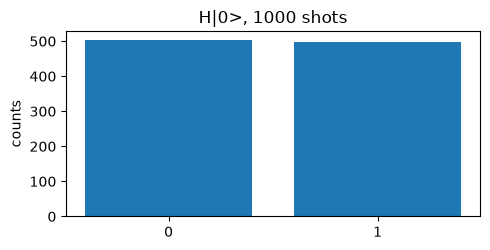

In [10]:
class QSim:
    """A tiny statevector simulator. Methods return self, so calls can be chained."""
    def __init__(self, n):
        self.n = n
        self.psi = np.zeros(2 ** n, dtype=complex)
        self.psi[0] = 1.0                      # start in |00...0>
    def gate(self, U, *qubits):
        self.psi = apply_gate(self.psi, U, qubits, self.n); return self
    def x(self, q):  return self.gate(X, q)
    def y(self, q):  return self.gate(Y, q)
    def z(self, q):  return self.gate(Z, q)
    def h(self, q):  return self.gate(H, q)
    def s(self, q):  return self.gate(S, q)
    def t(self, q):  return self.gate(T, q)
    def rx(self, th, q): return self.gate(RX(th), q)
    def ry(self, th, q): return self.gate(RY(th), q)
    def rz(self, th, q): return self.gate(RZ(th), q)
    def cx(self, c, t): return self.gate(CNOT, c, t)
    def cz(self, a, b): return self.gate(CZ, a, b)
    def probs(self):
        return np.abs(self.psi) ** 2
    def measure(self, shots=1000, seed=0):
        """Sample bitstrings like a real device would. Returns a Counter."""
        rng = np.random.default_rng(seed)
        p = self.probs(); p = p / p.sum()
        idx = rng.choice(len(p), size=shots, p=p)
        return Counter(format(i, f"0{self.n}b") for i in idx)

def bitstrings(n):
    return [format(i, f"0{n}b") for i in range(2 ** n)]

def plot_counts(counts, title="", ax=None):
    """Bar chart of measurement counts, with every bitstring on the x-axis."""
    n = len(next(iter(counts)))
    labels = bitstrings(n)
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 2.6))
    ax.bar(labels, [counts.get(b, 0) for b in labels], color="tab:blue")
    ax.set_title(title); ax.set_ylabel("counts")
    ax.tick_params(axis="x", rotation=90 if n > 3 else 0)
    plt.tight_layout()
    return ax

def show_state(psi, tol=1e-9):
    """Print the non-zero amplitudes of a state in ket notation."""
    n = int(np.log2(len(psi)))
    for i, a in enumerate(psi):
        if abs(a) > tol:
            print(f"  |{format(i, f'0{n}b')}>  amplitude {a.real:+.3f}{a.imag:+.3f}j   probability {abs(a)**2:.3f}")


# First run: one qubit, Hadamard, 1000 shots
sim = QSim(1).h(0)
show_state(sim.psi)
counts = sim.measure(shots=1000, seed=SEED)
print(counts)
plot_counts(counts, "H|0>, 1000 shots"); plt.show()

**What just happened?** About half the shots gave 0 and half gave 1, just like a fair coin. In the rest of the notebook (and in notebooks 02-04) we use this `QSim` class for every experiment. The whole simulator is about 60 lines.

## 8. CNOT and entanglement: the Bell state

**What it is.** **CNOT** (controlled-NOT) is a 2-qubit gate: if the **control** qubit is 1, it flips the **target** qubit; otherwise it does nothing. On basis states: 00→00, 01→01, 10→11, 11→10.

Apply H to qubit 0 and then CNOT(0→1):

$$\lvert00\rangle \xrightarrow{H} \tfrac{1}{\sqrt2}(\lvert00\rangle+\lvert10\rangle) \xrightarrow{CNOT} \tfrac{1}{\sqrt2}(\lvert00\rangle+\lvert11\rangle)$$

This is the **Bell state** $\lvert\Phi^+\rangle$. It is **entangled**: it cannot be written as (state of qubit 0) ⊗ (state of qubit 1). Each qubit on its own looks completely random, but the two results always agree.

**Simple analogy (with a warning).** Like a pair of gloves in two boxes: open one box, see "left", and you know the other is "right". The warning: with gloves the answer was fixed from the start. With entangled qubits, Bell's theorem and experiments show that no such pre-written answer can explain the correlations when you measure in different bases. Entanglement also **cannot send messages faster than light**: each side alone sees only random bits.

**When it matters.** Entanglement is a necessary resource for quantum speedups: a circuit that never creates much entanglement can usually be simulated efficiently on a classical computer.

  |00>  amplitude +0.707+0.000j   probability 0.500
  |11>  amplitude +0.707+0.000j   probability 0.500
Counter({'00': 503, '11': 497})  <- only 00 and 11 ever appear


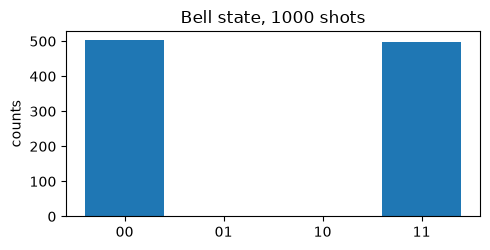

In [11]:
bell = QSim(2).h(0).cx(0, 1)
show_state(bell.psi)
counts = bell.measure(shots=1000, seed=SEED)
print(counts, " <- only 00 and 11 ever appear")
plot_counts(counts, "Bell state, 1000 shots"); plt.show()

In [12]:
def is_entangled(psi2):
    """A 2-qubit state is a product state exactly when its 2x2 amplitude matrix has rank 1.
    (The number of non-zero singular values is called the Schmidt rank.)"""
    sv = np.linalg.svd(psi2.reshape(2, 2), compute_uv=False)
    return int(np.sum(sv > 1e-9)) > 1

print("|0>(x)|+>   entangled?", is_entangled(QSim(2).h(1).psi))
print("Bell state  entangled?", is_entangled(bell.psi))

# The four Bell states
for name, prep in [("Phi+", lambda s: s), ("Phi-", lambda s: s.z(0)), ("Psi+", lambda s: s.x(1)), ("Psi-", lambda s: s.x(1).z(0))]:
    s = prep(QSim(2).h(0).cx(0, 1))
    print(f"{name}: ", end=""); print(", ".join(f"{b}:{a.real:+.3f}" for b, a in zip(bitstrings(2), s.psi) if abs(a) > 1e-9))

# A 3-qubit GHZ state: (|000> + |111>)/sqrt(2)
ghz = QSim(3).h(0).cx(0, 1).cx(1, 2)
print("GHZ counts:", ghz.measure(1000, seed=SEED))

|0>(x)|+>   entangled? False
Bell state  entangled? True
Phi+: 00:+0.707, 11:+0.707
Phi-: 00:+0.707, 11:-0.707
Psi+: 01:+0.707, 10:+0.707
Psi-: 01:+0.707, 10:-0.707
GHZ counts: Counter({'000': 503, '111': 497})


## 9. Interference: amplitudes can cancel

**What it is.** **Interference** happens when two "paths" to the same outcome have amplitudes that add (**constructive**) or cancel (**destructive**). Probabilities can never cancel (they are never negative), but amplitudes can, because they have signs and phases.

**Simple analogy.** Noise-cancelling headphones: a sound wave plus its upside-down copy gives silence. Quantum algorithms are "noise-cancelling for wrong answers": they make the paths to wrong answers cancel and the paths to the right answer add up.

**How it works.** H on $\lvert0\rangle$ gives 50/50. A second H brings it back to $\lvert0\rangle$ with certainty:

$$H\lvert+\rangle = \tfrac{1}{\sqrt2}\left(\tfrac{\lvert0\rangle+\lvert1\rangle}{\sqrt2}+\tfrac{\lvert0\rangle-\lvert1\rangle}{\sqrt2}\right)=\lvert0\rangle$$

The two paths to $\lvert1\rangle$ have amplitudes $+\tfrac12$ and $-\tfrac12$ and cancel. If we put a Z in the middle, it flips one sign and now the paths to $\lvert0\rangle$ cancel instead.

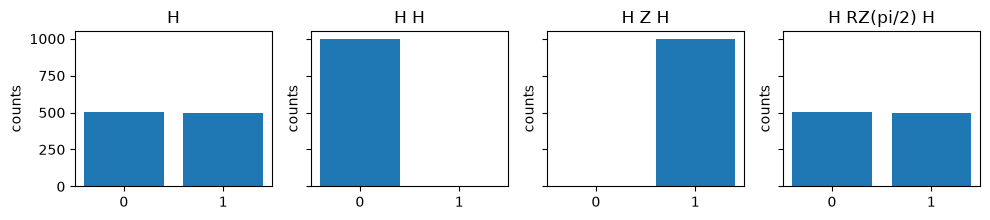

In [13]:
experiments = {
    "H":        QSim(1).h(0),             # one H: 50/50
    "H H":      QSim(1).h(0).h(0),        # two H: back to 0 (destructive interference on 1)
    "H Z H":    QSim(1).h(0).z(0).h(0),   # a hidden phase flip becomes a visible 1
    "H RZ(pi/2) H": QSim(1).h(0).rz(np.pi/2, 0).h(0),  # a quarter phase: 50/50 again
}
fig, axes = plt.subplots(1, 4, figsize=(10, 2.3), sharey=True)
for ax, (name, s) in zip(axes, experiments.items()):
    plot_counts(s.measure(1000, seed=SEED), name, ax=ax)
plt.show()

**What just happened?** The phase that Z adds is invisible if you measure right after it, but the second H turns that phase difference into a different outcome. This "phase, then interfere" pattern is the core of Deutsch-Jozsa, Grover and the quantum Fourier transform in notebook 02.

## 10. No-cloning: you cannot copy an unknown qubit

**What it is.** The **no-cloning theorem** says there is no machine (no unitary gate) that takes an *unknown* state $\lvert\psi\rangle$ and outputs two copies $\lvert\psi\rangle\lvert\psi\rangle$.

**Simple analogy.** You can photocopy a page, but you cannot photocopy a spinning coin's spin without stopping it.

**Why it matters.**
- You cannot "save a backup copy" of quantum data or read it many times. This is one reason quantum error correction is hard (notebook 04).
- It is the basis of quantum key distribution security: an eavesdropper cannot copy the qubits without disturbing them.
- For machine learning it means quantum data cannot be inspected for free; every look costs a fresh copy of the state.

**Tiny demo.** CNOT copies the basis states: $\lvert0\rangle\lvert0\rangle\to\lvert0\rangle\lvert0\rangle$ and $\lvert1\rangle\lvert0\rangle\to\lvert1\rangle\lvert1\rangle$. Does it also copy $\lvert+\rangle$? We measure the **fidelity** (how close two states are, $\lvert\langle a\vert b\rangle\rvert^2$, 1 = identical, 0 = completely different) between the output and the wanted $\lvert+\rangle\lvert+\rangle$.

In [14]:
def fidelity(a, b):
    return abs(np.vdot(a, b)) ** 2

for name, prep in [("|0>", lambda s: s), ("|1>", lambda s: s.x(0)), ("|+>", lambda s: s.h(0))]:
    single = prep(QSim(1)).psi                      # the state we want to copy
    wanted = np.kron(single, single)                # two perfect copies
    out = prep(QSim(2)).cx(0, 1).psi                # the "CNOT copier": copy qubit 0 onto blank qubit 1
    print(f"copy {name}: fidelity with two copies = {fidelity(out, wanted):.2f}")

copy |0>: fidelity with two copies = 1.00
copy |1>: fidelity with two copies = 1.00
copy |+>: fidelity with two copies = 0.50


**What just happened?** The copier works perfectly for $\lvert0\rangle$ and $\lvert1\rangle$ (fidelity 1.00) but not for $\lvert+\rangle$ (fidelity 0.50): it creates a Bell state instead of two copies. The theorem proves that *every* possible copier fails for some states. Copying *known* classical information is fine; copying *unknown* superpositions is impossible.

## 11. Putting it together: a tiny circuit, end to end

Let us combine everything: superposition, a rotation, entanglement and measurement on 3 qubits. We also check our simulator against a "slow but obviously correct" version that multiplies big Kronecker matrices.

  |000>  amplitude +0.612+0.000j   probability 0.375
  |011>  amplitude +0.354+0.000j   probability 0.125
  |101>  amplitude +0.612+0.000j   probability 0.375
  |110>  amplitude +0.354+0.000j   probability 0.125
matches the slow Kronecker version: True


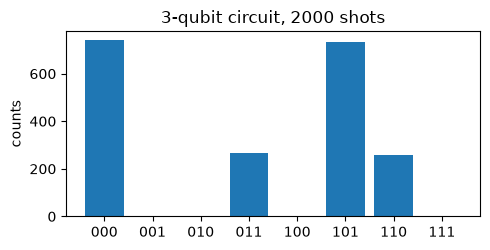

Check: in every outcome, bit 2 = bit 0 XOR bit 1 -> True


In [15]:
# Circuit: H on q0, RY(pi/3) on q1, CNOT q0->q2, CNOT q1->q2
sim = QSim(3).h(0).ry(np.pi / 3, 1).cx(0, 2).cx(1, 2)
show_state(sim.psi)

# Slow check with full 8x8 matrices
def kron_all(*ms):
    out = np.array([[1]], dtype=complex)
    for m in ms: out = np.kron(out, m)
    return out
P0, P1 = np.diag([1, 0]), np.diag([0, 1])                       # projectors |0><0| and |1><1|
cx02 = kron_all(P0, I2, I2) + kron_all(P1, I2, X)              # CNOT 0->2
cx12 = kron_all(I2, P0, I2) + kron_all(I2, P1, X)              # CNOT 1->2
psi = np.zeros(8, complex); psi[0] = 1
psi = cx12 @ cx02 @ kron_all(H, RY(np.pi / 3), I2) @ psi
print("matches the slow Kronecker version:", np.allclose(psi, sim.psi))

counts = sim.measure(shots=2000, seed=SEED)
plot_counts(counts, "3-qubit circuit, 2000 shots"); plt.show()
print("Check: in every outcome, bit 2 = bit 0 XOR bit 1 ->",
      all(int(b[2]) == int(b[0]) ^ int(b[1]) for b in counts))

## 12. Recap (cheat sheet)

| Term | One-line meaning |
|---|---|
| Qubit | a 2-amplitude vector $\alpha\lvert0\rangle+\beta\lvert1\rangle$ with $\lvert\alpha\rvert^2+\lvert\beta\rvert^2=1$ |
| Amplitude | a (complex) number per outcome; its squared size is the probability |
| Born rule | P(outcome) = $\lvert\text{amplitude}\rvert^2$ |
| Superposition | a state with non-zero amplitude on more than one outcome |
| Measurement | gives a classical bit at random and collapses the state |
| Shot | one run of the circuit + measurement; results are counted over many shots |
| Phase | the sign or complex angle of an amplitude; invisible directly, visible through interference |
| Bloch sphere | the picture of one qubit as a point on a ball; gates are rotations |
| Gate | a unitary matrix; X (NOT), Z (phase flip), H (superposition), S, T, RX/RY/RZ (rotations), CNOT (controlled NOT) |
| Tensor product | how independent qubits combine; n qubits = $2^n$ amplitudes |
| Entanglement | a joint state that is not a product of single-qubit states (e.g. the Bell state) |
| Interference | amplitudes adding or cancelling; the engine of quantum algorithms |
| No-cloning | an unknown quantum state cannot be copied |
| Statevector simulator | keep all $2^n$ amplitudes in memory and multiply by gates; exact but exponential cost |

## 13. Interview questions

1. **What is the difference between a bit and a qubit?** A bit is 0 or 1. A qubit has two complex amplitudes; measuring gives 0 or 1 with probabilities equal to the squared sizes of the amplitudes.
2. **Does a quantum computer try all answers in parallel?** Not in a useful sense. You get only n bits from one measurement. Algorithms must use interference so the right answer becomes likely.
3. **Why must gates be unitary?** To keep the total probability equal to 1 and make the evolution reversible.
4. **What does the Hadamard gate do?** It maps $\lvert0\rangle$ to $\lvert+\rangle$ and $\lvert1\rangle$ to $\lvert-\rangle$ (equal superpositions with different relative phase), and it is its own inverse.
5. **$\lvert+\rangle$ and $\lvert-\rangle$ give the same measurement statistics. Are they the same state?** No. They differ by a relative phase; an H gate before measuring turns them into $\lvert0\rangle$ and $\lvert1\rangle$.
6. **How do you create a Bell state?** H on qubit 0, then CNOT from qubit 0 to qubit 1.
7. **Can entanglement send information faster than light?** No. Each side alone sees random bits; the correlation is visible only after comparing results over a normal channel.
8. **Why is classical simulation of quantum circuits hard?** A general n-qubit state needs $2^n$ amplitudes, so memory and time grow exponentially.
9. **What is the no-cloning theorem and why does it matter?** No unitary copies an unknown state. It makes error correction harder and protects quantum key distribution.
10. **Why do we need many shots?** Each shot gives one random outcome; probabilities and expectation values are estimated from counts, with error about $1/\sqrt{\text{shots}}$.

## 14. Further reading

- M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, Cambridge University Press (10th anniversary edition, 2010). Chapters 1, 2 and 4 cover everything in this notebook.
- The Qiskit documentation and the IBM Quantum Learning courses (successor of the free "Qiskit Textbook"), for example "Basics of quantum information".
- PennyLane documentation and the "Quantum computing" and QML demos at pennylane.ai.
- J. Preskill, "Quantum Computing in the NISQ era and beyond", *Quantum* 2, 79 (2018), arXiv:1801.00862. A short, honest overview of what near-term machines can do.
- R. P. Feynman, "Simulating physics with computers", *International Journal of Theoretical Physics* 21 (1982).
- M. Schuld and F. Petruccione, *Machine Learning with Quantum Computers*, Springer (2nd ed., 2021). Chapter on quantum computing basics, aimed at ML readers.

## Where to go next

- [02_quantum_algorithms.ipynb](02_quantum_algorithms.ipynb): Deutsch-Jozsa, Grover, the quantum Fourier transform, Shor, VQE and QAOA with this simulator.
- [03_quantum_machine_learning.ipynb](03_quantum_machine_learning.ipynb): data encoding, variational classifiers, quantum kernels and their limits.
- [04_quantum_ai_tools_hardware_and_industry.ipynb](04_quantum_ai_tools_hardware_and_industry.ipynb): Qiskit, PennyLane, hardware, noise, error correction and post-quantum cryptography.
- Track overview: [README.md](README.md). Notes: [notes/25_Quantum_AI.md](notes/25_Quantum_AI.md).
- Maths refreshers: [linear algebra](../14_Mathematics/01_linear_algebra.ipynb), [probability](../14_Mathematics/03_probability.ipynb).